<a href="https://colab.research.google.com/github/PriyankaAntony/qsar-fish-toxicity-ml/blob/main/aquatictoxity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Welcome to Colab!

In [118]:
import pandas as pd

df = pd.read_excel("qsar_fish_toxicity.xlsx", header=None)
if df.iloc[0].apply(lambda v: isinstance(v, str)).any():  # drop a header row if there is one
    df = df.iloc[1:].reset_index(drop=True)
df = df.astype(float)
print(df.shape)  # should print (908, 7)
print(df.head())
df.to_csv("qsar_fish_toxicity.csv", sep=";", header=False, index=False)

(908, 7)
       0      1      2    3    4      5      6
0  3.260  0.829  1.676  0.0  1.0  1.453  3.770
1  2.189  0.580  0.863  0.0  0.0  1.348  3.115
2  2.125  0.638  0.831  0.0  0.0  1.348  3.531
3  3.027  0.331  1.472  1.0  0.0  1.807  3.510
4  2.094  0.827  0.860  0.0  0.0  1.886  5.390


In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split

DATA_FILE = "qsar_fish_toxicity.csv"
LOG_RESPONSE = False   # True = model log(LC50); metrics are reported on the LC50 scale
SEED = 42

cols = ["CIC0", "SM1_Dz", "GATS1i", "NdsCH", "NdssC", "MLOGP", "LC50"]
df = pd.read_csv(DATA_FILE, sep=";", header=None, names=cols)

# 1. Exploratory data analysis
print(df.shape)
print(df.describe())
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicated rows:", int(df.duplicated().sum()))

(908, 7)
             CIC0      SM1_Dz      GATS1i       NdsCH       NdssC       MLOGP  \
count  908.000000  908.000000  908.000000  908.000000  908.000000  908.000000   
mean     2.898129    0.628468    1.293591    0.229075    0.485683    2.109285   
std      0.756088    0.428459    0.394303    0.605335    0.861279    1.433181   
min      0.667000    0.000000    0.396000    0.000000    0.000000   -2.884000   
25%      2.347000    0.223000    0.950750    0.000000    0.000000    1.209000   
50%      2.934000    0.570000    1.240500    0.000000    0.000000    2.127000   
75%      3.407000    0.892750    1.562250    0.000000    1.000000    3.105000   
max      5.926000    2.171000    2.920000    4.000000    6.000000    6.515000   

             LC50  
count  908.000000  
mean     4.064431  
std      1.455698  
min      0.053000  
25%      3.151750  
50%      3.987500  
75%      4.907500  
max      9.612000  
Missing values: 0
Duplicated rows: 1


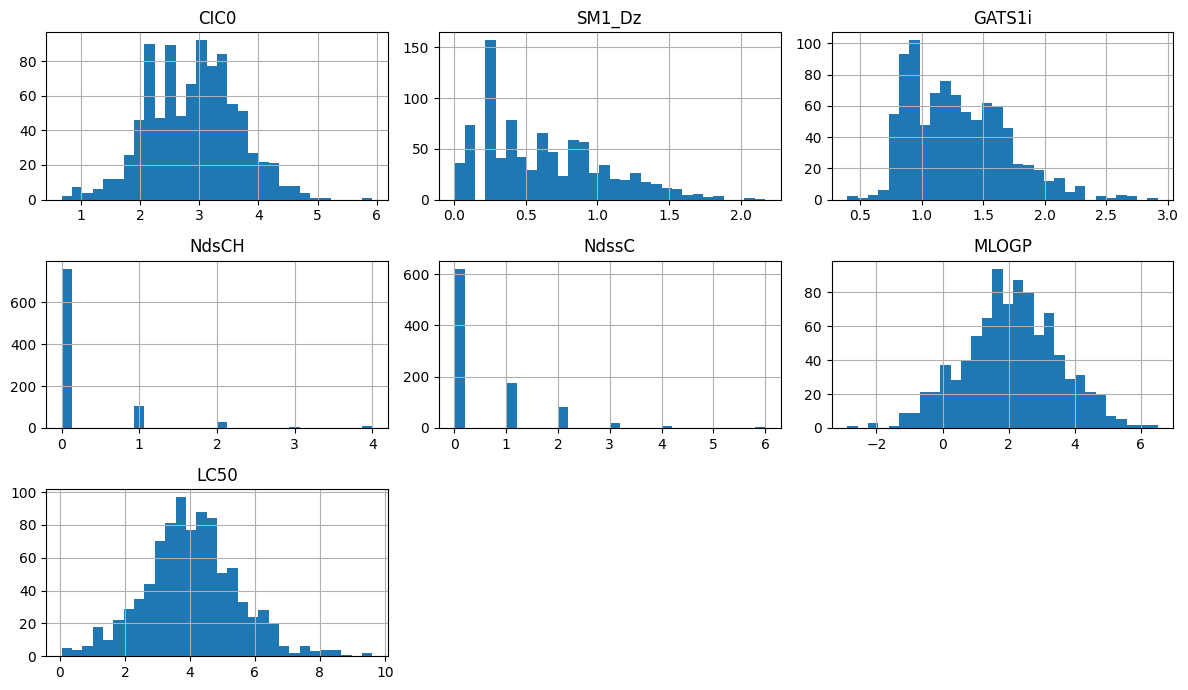

In [120]:
df.hist(figsize=(12, 7), bins=30)
plt.tight_layout()
plt.savefig("histograms.png")
plt.show()

In [121]:
# 2. Outlier removal (boxplot / IQR rule, one pass over all columns)
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
outlier = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).any(axis=1)
df_clean = df[~outlier].copy()
print("Rows before:", len(df), " after outlier removal:", len(df_clean))

Rows before: 908  after outlier removal: 710


        CIC0  SM1_Dz  GATS1i  NdsCH  NdssC  MLOGP  LC50
CIC0    1.00   -0.28    0.20    NaN   0.14   0.40  0.25
SM1_Dz -0.28    1.00   -0.16    NaN   0.10   0.20  0.45
GATS1i  0.20   -0.16    1.00    NaN   0.13  -0.43 -0.41
NdsCH    NaN     NaN     NaN    NaN    NaN    NaN   NaN
NdssC   0.14    0.10    0.13    NaN   1.00  -0.09 -0.00
MLOGP   0.40    0.20   -0.43    NaN  -0.09   1.00  0.70
LC50    0.25    0.45   -0.41    NaN  -0.00   0.70  1.00


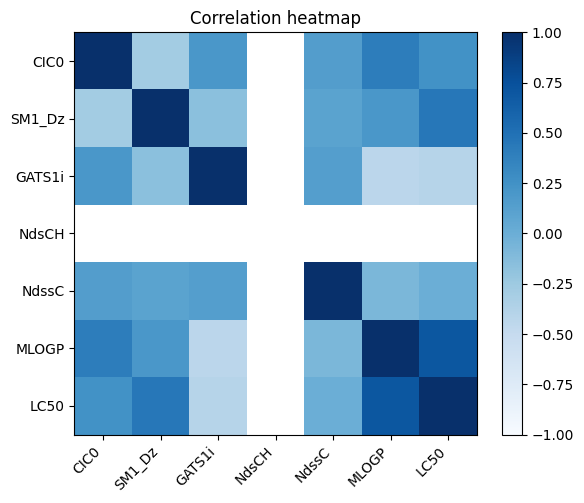

In [122]:
# 3. Correlation analysis
corr = df_clean.corr()
print(corr.round(2))
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="Blues", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols)
fig.colorbar(im)
ax.set_title("Correlation heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png")
plt.show()

In [123]:
# 4. Train/test split (85 : 15)
X = df_clean.drop(columns="LC50")
y = df_clean["LC50"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=SEED)


In [124]:
# 5. Linear regression
model = LinearRegression()
model.fit(X_train, np.log(y_train) if LOG_RESPONSE else y_train)
print(dict(zip(X.columns, model.coef_.round(3))), "intercept:", round(model.intercept_, 3))


{'CIC0': np.float64(0.393), 'SM1_Dz': np.float64(1.181), 'GATS1i': np.float64(-0.67), 'NdsCH': np.float64(0.0), 'NdssC': np.float64(-0.027), 'MLOGP': np.float64(0.441)} intercept: 1.968


In [125]:
def predict_lc50(features):
    pred = model.predict(features)
    return np.exp(pred) if LOG_RESPONSE else pred

In [126]:
# 6. Evaluation on training AND test data
pred_train, pred_test = predict_lc50(X_train), predict_lc50(X_test)
results = pd.DataFrame({
    "set": ["train", "test"],
    "R2": [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],
    "RMSE": [np.sqrt(mean_squared_error(y_train, pred_train)),
             np.sqrt(mean_squared_error(y_test, pred_test))],
})
print(results.round(3))

     set     R2   RMSE
0  train  0.608  0.814
1   test  0.659  0.793


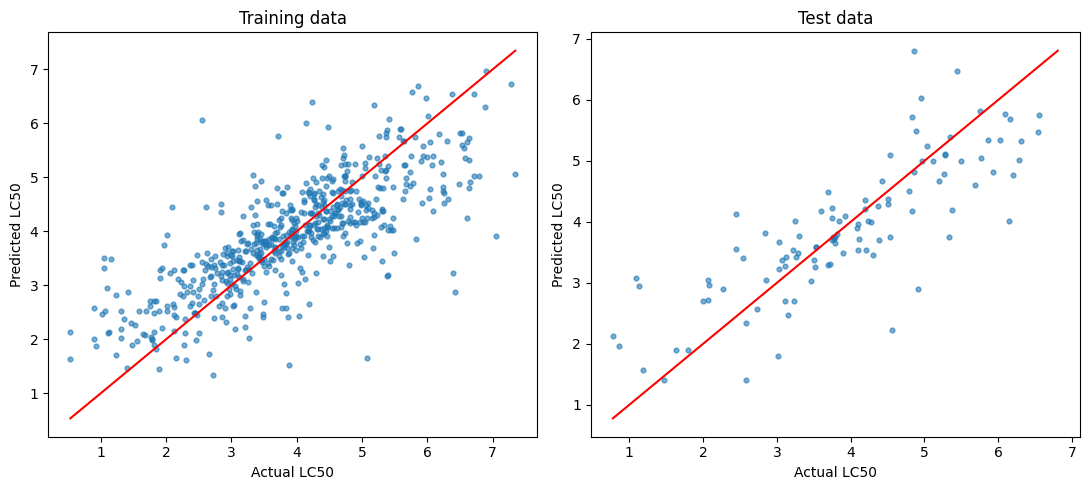

In [127]:
# 7. Actual vs predicted
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, actual, pred, title in [(axes[0], y_train, pred_train, "Training data"),
                                (axes[1], y_test, pred_test, "Test data")]:
    ax.scatter(actual, pred, s=12, alpha=0.6)
    lims = [min(actual.min(), pred.min()), max(actual.max(), pred.max())]
    ax.plot(lims, lims, color="red")
    ax.set_xlabel("Actual LC50")
    ax.set_ylabel("Predicted LC50")
    ax.set_title(title)
plt.tight_layout()
plt.savefig("actual_vs_predicted.png")
plt.show()

In [128]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

models = {
    "Linear regression": LinearRegression(),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "kNN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=7)),
    "Random forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient boosting": GradientBoostingRegressor(random_state=42),
}
for name, m in models.items():
    r2 = cross_val_score(m, X, y, cv=5, scoring="r2")
    rmse = -cross_val_score(m, X, y, cv=5, scoring="neg_root_mean_squared_error")
    print(f"{name:20s} R2 {r2.mean():.3f}   RMSE {rmse.mean():.3f}")

Linear regression    R2 0.585   RMSE 0.816
Ridge                R2 0.585   RMSE 0.816
kNN                  R2 0.610   RMSE 0.792
Random forest        R2 0.629   RMSE 0.771
Gradient boosting    R2 0.621   RMSE 0.779
